Principal Component Analysis for Backgorund and Foreground separation

In [7]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Importing the data and processing each frame and flattening them and appending them to prepare a matrix X  which has n x m dimensions where n represents the number of frames and m represents the pixels 

In [8]:
DATASET_PATH = "../data/highway/input"

image_files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".jpg")
])

In [9]:
frames = []

for file in image_files[500:600]:

    img_path = os.path.join(DATASET_PATH, file)

    frame = cv2.imread(img_path)

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    gray = cv2.resize(gray, (160,120))

    x = gray.flatten().astype(np.float32)

    frames.append(x)

In [10]:
X = np.column_stack(frames)

print(X.shape)
print(X.dtype)

(19200, 100)
float32


PCA needs mean centering :
Reason : need to learn

In [11]:
mean_frame = np.mean(X, axis=1, keepdims=True)

X_centered = X - mean_frame

We are finding the singular values of the matrix x and left singular vectors (column vectors of U) and right singular vectors (column vectors of V) using singular value decomposition technique which says x^Tx -> eigen vectors of this gives right singular vectors and xx^T gives the left singular vectors 

In [12]:
U, S, VT = np.linalg.svd(X_centered, full_matrices=False)

print(S.shape)

(100,)


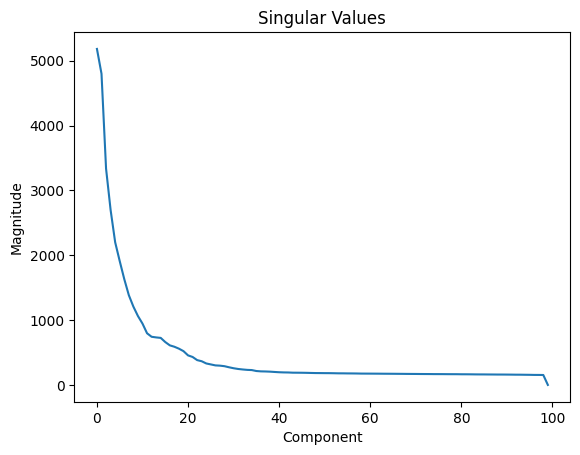

In [13]:
plt.plot(S)
plt.title("Singular Values")
plt.xlabel("Component")
plt.ylabel("Magnitude")
plt.show()

To find the ideal K value we plot the graph for k vs frobenius norm of x - x' and we choose the knee point in the graph which will be the ideal value of K

In [17]:
errors_squared = []
errors = []
k_values = range(1,101)

for k in k_values:
    # ||X - X_k||_F^2
    error_squared = np.sum(S[k+1:] ** 2)
    # ||X - X_k||_F
    error = np.sqrt(error_squared)

    errors_squared.append(error_squared)
    errors.append(error)
    

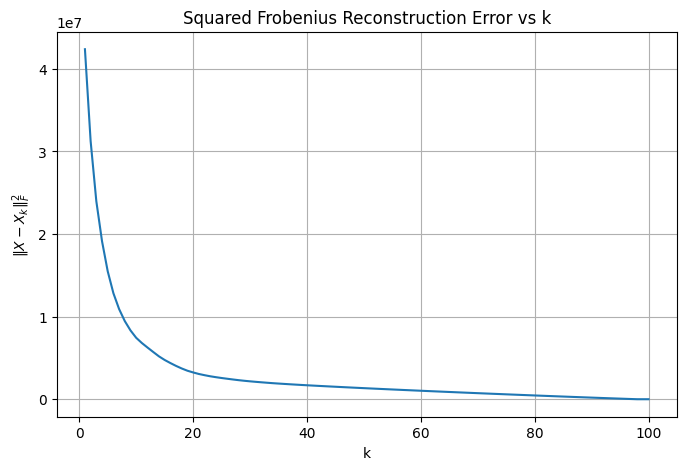

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, errors_squared)

plt.xlabel("k")
plt.ylabel(r"$\|X - X_k\|_F^2$")
plt.title("Squared Frobenius Reconstruction Error vs k")
plt.grid(True)

plt.show()

In [63]:
k=2

In [64]:
Uk = U[:, :k]
Sk = S[:k]
VTk = VT[:k, :]
X_reconstructed = (Uk * Sk) @ VTk

/var/folders/jb/4w53x6j16lg901xfnf6463dr0000gn/T/ipykernel_4354/2019603319.py:4: RuntimeWarning: divide by zero encountered in matmul
  X_reconstructed = (Uk * Sk) @ VTk
/var/folders/jb/4w53x6j16lg901xfnf6463dr0000gn/T/ipykernel_4354/2019603319.py:4: RuntimeWarning: overflow encountered in matmul
  X_reconstructed = (Uk * Sk) @ VTk
/var/folders/jb/4w53x6j16lg901xfnf6463dr0000gn/T/ipykernel_4354/2019603319.py:4: RuntimeWarning: invalid value encountered in matmul
  X_reconstructed = (Uk * Sk) @ VTk


In [65]:
X_reconstructed += mean_frame

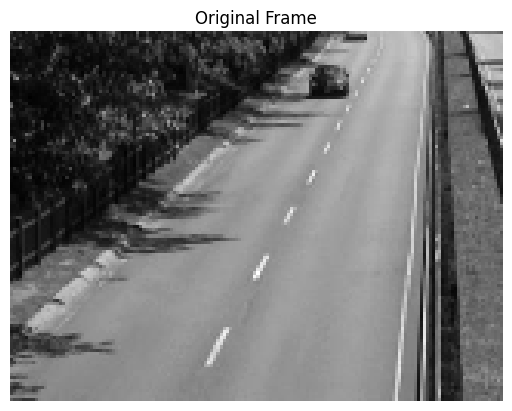

In [66]:
original = X[:,78].reshape(120,160)

plt.imshow(original, cmap='gray')
plt.title("Original Frame")
plt.axis("off")
plt.show()

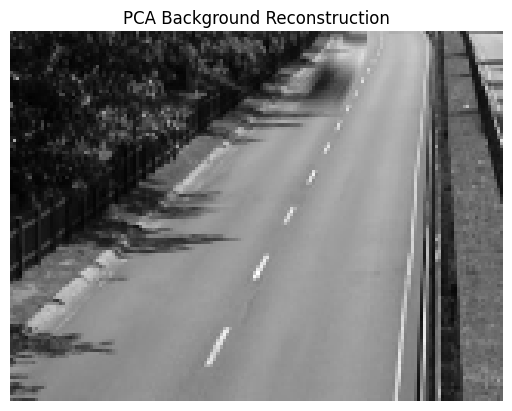

In [67]:
background = X_reconstructed[:,78].reshape(120,160)

plt.imshow(background, cmap='gray')
plt.title("PCA Background Reconstruction")
plt.axis("off")
plt.show()

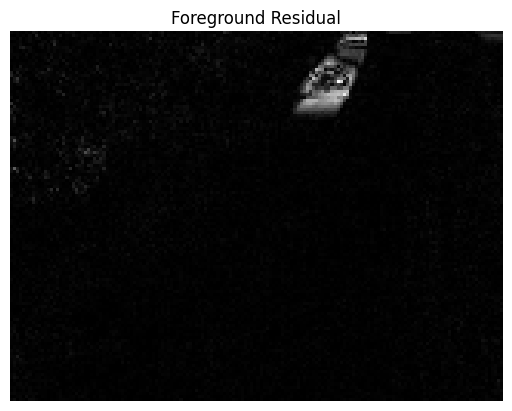

6.1035156e-05
87.63768
1.6219467


In [68]:
foreground = np.abs(
    X[:,78] - X_reconstructed[:,78]
)

foreground = foreground.reshape(120,160)

plt.imshow(foreground, cmap='gray')
plt.title("Foreground Residual")
plt.axis("off")
plt.show()

print(np.min(foreground))
print(np.max(foreground))
print(np.mean(foreground))

In [69]:
Ground_path = "../data/highway/groundtruth"

In [70]:
sorted(os.listdir(Ground_path))[:5]

['.ipynb_checkpoints',
 'gt000001.png',
 'gt000002.png',
 'gt000003.png',
 'gt000004.png']

Storing the ground truth mask for calculating precision accuracy and F1 score 

In [93]:
gt_files = sorted([
    f for f in os.listdir(Ground_path)
    if f.endswith(".png")
])

In [94]:
gt_masks = []

for file in gt_files[500:600]:

    gt_path = os.path.join(Ground_path, file)

    gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)

    gt = cv2.resize(gt, (160,120))

    gt_binary = (gt>0).astype(np.uint8)

    gt_masks.append(gt_binary)
    

Finding the appropriate threshold values so that the method is performing well. To find we iterarte through various values of threshold and k values to find the appropriate values of each.

In [118]:
k_values = range(1,21)

In [119]:
results = []

In [120]:
results = []

for threshold in range(10,30,2):

    for k in k_values:

        # reconstruction
        Uk = U[:, :k]
        Sk = S[:k]
        VTk = VT[:k, :]

        X_reconstructed = np.dot(
            Uk * Sk,
            VTk
        )

        X_reconstructed += mean_frame

        pred_masks = []

        # generate masks
        for i in range(100):

            foreground = np.abs(
                X[:, i] - X_reconstructed[:, i]
            )

            foreground = foreground.reshape(120,160)

            mask = (
                foreground > threshold
            ).astype(np.uint8)

            pred_masks.append(mask)

        # flatten
        y_pred = np.concatenate([
            m.flatten() for m in pred_masks
        ])

        y_true = np.concatenate([
            g.flatten() for g in gt_masks
        ])

        # confusion matrix
        TP = np.sum((y_pred == 1) & (y_true == 1))

        TN = np.sum((y_pred == 0) & (y_true == 0))

        FP = np.sum((y_pred == 1) & (y_true == 0))

        FN = np.sum((y_pred == 0) & (y_true == 1))

        # metrics
        precision = TP / (TP + FP + 1e-8)

        recall = TP / (TP + FN + 1e-8)

        f1 = (
            2 * precision * recall
            / (precision + recall + 1e-8)
        )

        acc = (TP+TN)/(TP+TN+FP+FN+1e-8)

        # STORE RESULTS
        results.append({
            "threshold": threshold,
            "k": k,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "accuracy":acc
        })

        

In [121]:
df = pd.DataFrame(results)
display(df[df['k'] == 15])

,threshold,k,precision,recall,f1,accuracy
14,10,15,0.893761,0.295941,0.444650,0.993105
34,12,15,0.938674,0.231615,0.371551,0.992692
54,14,15,0.965446,0.182534,0.307020,0.992314
74,16,15,0.979969,0.142051,0.248135,0.991970
94,18,15,0.992915,0.109554,0.197335,0.991687
114,20,15,0.995979,0.082975,0.153188,0.991443
134,22,15,0.997255,0.060863,0.114725,0.991239
154,24,15,0.998742,0.044335,0.084902,0.991085
174,26,15,0.998243,0.031716,0.061479,0.990968
194,28,15,0.997625,0.023452,0.045827,0.990891


In [124]:
best = df.loc[df["f1"].idxmax()]

print(best)

threshold    10.000000
k             7.000000
precision     0.689795
recall        0.569546
f1            0.623930
accuracy      0.993596
Name: 6, dtype: float64


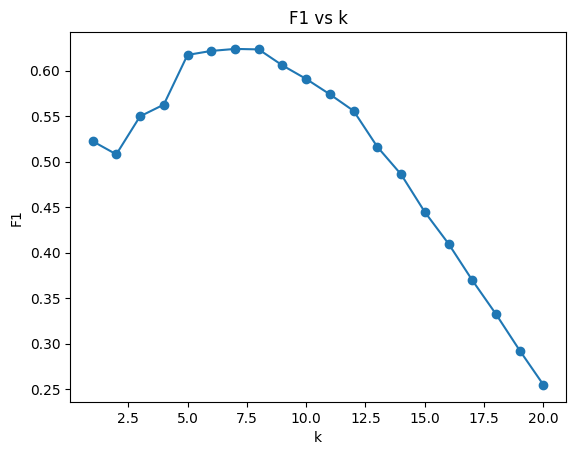

In [125]:
subset = df[df["threshold"] == 10]

plt.plot(
    subset["k"],
    subset["f1"],
    marker='o'
)

plt.xlabel("k")
plt.ylabel("F1")
plt.title("F1 vs k")
plt.grid(False)
plt.show()

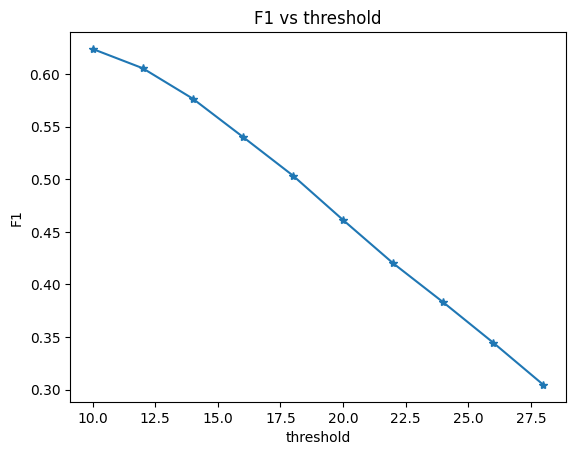

In [126]:
subset = df[df["k"] == 7]

plt.plot(
    subset["threshold"],
    subset["f1"],
    marker='*'
)

plt.xlabel("threshold")
plt.ylabel("F1")
plt.title("F1 vs threshold")
plt.grid(False)
plt.show()